# 6. Hafta — Doğrusal ve Lojistik Regresyon

**BTP271 Uygulamalı Yapay Zeka** · Ön-Yüz Yazılım Geliştirme
Öğr. Gör. Çisem YAŞAR · cyasar@gelisim.edu.tr

---
## Veriyi hazırla
Aşağıdaki hücre ev verisini ve temiz tabloyu (`temiz`) yeniden oluşturur. Sadece çalıştır.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_metni = """ilan_id,semt,metrekare,oda_sayisi,bina_yasi,kat,fiyat
1,Avcılar,95,2,12,3,4250000
2,Avcılar,120,3,5,2,5900000
3,Beylikdüzü,140,3,3,7,6800000
4,Kadıköy,85,2,25,4,9500000
5,Beşiktaş,110,3,30,2,13200000
6,Esenyurt,100,2,2,5,3600000
7,Avcılar,150,4,,1,7100000
8,Kadıköy,130,3,15,3,14500000
9,Beylikdüzü,90,2,8,10,4100000
10,Esenyurt,135,3,4,8,4700000
11,Beşiktaş,75,1,40,1,
12,Avcılar,110,3,20,4,5200000
13,Kadıköy,160,4,,6,19800000
14,Beylikdüzü,180,4,1,3,8900000
15,Esenyurt,80,1,6,2,
9,Beylikdüzü,90,2,8,10,4100000
"""
with open("evler.csv", "w", encoding="utf-8") as f:
    f.write(csv_metni)

df = pd.read_csv("evler.csv")
temiz = df.drop_duplicates().dropna(subset=["fiyat"])
temiz = temiz.fillna({"bina_yasi": temiz["bina_yasi"].median()})
print(temiz.shape)

(13, 7)


---
## 1. Doğrusal regresyon: Noktalardan geçen en iyi çizgi

4. haftadaki saçılım grafiğini hatırla: metrekare arttıkça fiyat artıyordu. Doğrusal regresyon bu noktalardan geçen **en iyi düz çizgiyi** bulur:

$$\text{fiyat} = a \times \text{metrekare} + b$$

- **a (eğim):** Metrekare 1 artınca fiyat ortalama kaç TL artar?
- **b (kesişim):** Çizginin dikey ekseni kestiği nokta.
- **En iyi çizgi:** Noktalarla çizgi arasındaki farkların (**hataların**) en küçük olduğu çizgi.

5. haftada en iyi eşiği döngüyle aramıştık. Burada aranan şey eğim ve kesişim; scikit-learn bunları matematikle, tek adımda bulur.

### Scikit-learn'ün üç adımlık kalıbı
Scikit-learn'deki **tüm** modeller aynı kalıpla çalışır:
1. **Oluştur:** `model = LinearRegression()`
2. **Eğit:** `model.fit(X, y)`
3. **Tahmin et:** `model.predict(X_yeni)`

> ⚠️ `X` her zaman bir **tablo** (DataFrame) olmalı. Tek sütun bile olsa **çift köşeli parantez** kullan: `temiz[["metrekare"]]`

Eğim (a):    69,912 TL / m²
Kesişim (b): -358,330 TL


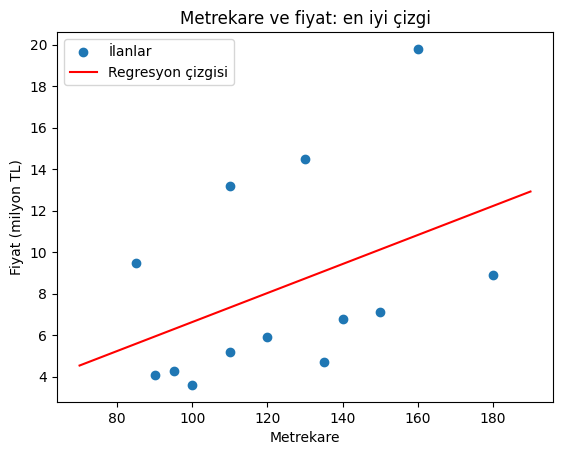

In [2]:
from sklearn.linear_model import LinearRegression

X = temiz[["metrekare"]]     # tablo (çift köşeli parantez)
y = temiz["fiyat"]           # tek sütun

model = LinearRegression()   # 1) oluştur
model.fit(X, y)              # 2) eğit

print(f"Eğim (a):    {model.coef_[0]:,.0f} TL / m²")
print(f"Kesişim (b): {model.intercept_:,.0f} TL")

# Çizgiyi noktaların üzerine çiz
xs = pd.DataFrame({"metrekare": [70, 190]})
plt.scatter(temiz["metrekare"], temiz["fiyat"] / 1e6, label="İlanlar")
plt.plot(xs["metrekare"], model.predict(xs) / 1e6, color="red", label="Regresyon çizgisi")   # 3) tahmin et
plt.title("Metrekare ve fiyat: en iyi çizgi")
plt.xlabel("Metrekare")
plt.ylabel("Fiyat (milyon TL)")
plt.legend()
plt.show()

#### ✍️ Kendin Yaz — Tahmin et ve hatayı ölç
1. 100, 150 ve 200 m²'lik evler için fiyat tahmini yap. Tahminleri `tahminler` değişkenine ata ve milyon TL olarak yazdır.
2. Modelin `temiz` tablosundaki **tüm evler** için tahminlerini hesapla; gerçek fiyattan çıkararak `hatalar` Series'ini oluştur.
3. **Ortalama mutlak hatayı (MAE)** hesapla ve `mae_m2` değişkenine ata: hataların mutlak değerlerinin ortalaması (`.abs().mean()`).
   MAE, "model ortalama kaç TL yanılıyor?" sorusunun cevabıdır.
4. Yorum satırına cevapla: Model en çok hangi semtteki evlerde yanılıyor? Neden olabilir?
   

In [ ]:
# kodunu yaz


# Cevabım:

In [ ]:
# 🧪 Test hücresi — değiştirme, sadece çalıştır
assert len(tahminler) == 3
assert abs(tahminler[1] - 10_128_426) < 1000
assert abs(mae_m2 - 3_773_253) < 1000
print("✅ Tüm testler geçti!")

---
## 2. Semti de ekleyelim: Kategorik kodlamanın uygulaması

5. haftada gördüğümüz **one-hot encoding** ile semti sayılara çevirip metrekarenin yanına ekleyeceğiz.
`pd.concat([tablo1, tablo2], axis=1)` iki tabloyu **yan yana** birleştirir.

In [3]:
semt_kodlu = pd.get_dummies(temiz["semt"], prefix="semt", dtype=int)
X_semt = pd.concat([temiz[["metrekare"]], semt_kodlu], axis=1)
X_semt.head()

,metrekare,semt_Avcılar,semt_Beylikdüzü,semt_Beşiktaş,semt_Esenyurt,semt_Kadıköy
0,95,1,0,0,0,0
1,120,1,0,0,0,0
2,140,0,1,0,0,0
3,85,0,0,0,0,1
4,110,0,0,1,0,0


#### ✍️ Kendin Yaz — Semt modeli
1. `X_semt` ve `y` ile yeni bir `LinearRegression` modeli eğit, `model_semt` değişkenine ata.
2. Bu modelin MAE değerini hesapla ve `mae_semt` değişkenine ata.
3. İki modelin MAE değerlerini milyon TL olarak yan yana yazdır.

Yorum satırına cevapla: Hata neden bu kadar azaldı?

In [ ]:
# kodunu yaz


# Cevabım:

In [ ]:
# 🧪 Test hücresi
assert len(model_semt.coef_) == 6
assert mae_semt < mae_m2
assert abs(mae_semt - 817_804) < 1000
print("✅ Tüm testler geçti!")

### Katsayıları okumak
Her sütunun katsayısı, o sütunun fiyata etkisini gösterir. Semt katsayıları, **aynı metrekaredeki** evler arasındaki farkı anlatır.

> ⚠️ **Dikkat:** Hatayı, modelin **eğitildiği** evler üzerinde ölçtük. 13 ev ve 6 öznitelikle model bu evleri kısmen **ezberlemiş** olabilir.
> Modeli hiç görmediği evlerde denemek gerekir. Bunuda **eğitim / test ayrımı** ile yapacağız.

In [4]:
katsayilar = pd.Series(model_semt.coef_, index=X_semt.columns)
print((katsayilar / 1e6).round(2).rename("milyon TL"))

NameError: name 'model_semt' is not defined

---
## 3. Lojistik regresyon: Adı regresyon, işi sınıflandırma

Doğrusal regresyon bir **sayı** tahmin eder. Peki "bu çiçek virginica mı?" gibi **evet / hayır** sorularında ne yapacağız?

**Lojistik regresyon**, doğrusal çizgiyi bir **S eğrisinden (sigmoid)** geçirir. Sonuç her zaman **0 ile 1 arasında bir olasılıktır**:
- Olasılık ≥ 0.5 → sınıf **1** (virginica)
- Olasılık < 0.5 → sınıf **0** (versicolor)

Önce hedef sütunu sayıya çevirelim. 5. haftada gördüğümüz **label encoding**: virginica → 1, versicolor → 0.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

df_iris = load_iris(as_frame=True).frame
df_iris["tur"] = df_iris["target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})

iki_tur = df_iris[df_iris["tur"] != "setosa"].copy()
iki_tur["virginica_mi"] = (iki_tur["tur"] == "virginica").astype(int)   # label encoding: 1 / 0

X_log = iki_tur[["petal width (cm)"]]
y_log = iki_tur["virginica_mi"]

log_model = LogisticRegression()
log_model.fit(X_log, y_log)

# S eğrisini çiz
xs = pd.DataFrame({"petal width (cm)": np.linspace(0.8, 2.7, 200)})
olasilik = log_model.predict_proba(xs)[:, 1]          # 1. sütun: "virginica olma" olasılığı
plt.scatter(X_log["petal width (cm)"], y_log, alpha=0.4, label="Çiçekler (0 = versicolor, 1 = virginica)")
plt.plot(xs["petal width (cm)"], olasilik, color="red", label="Virginica olasılığı")
plt.axhline(0.5, color="gray", linestyle="--", label="0.5 eşiği")
plt.title("Lojistik regresyon: S eğrisi")
plt.xlabel("Taç yaprağı genişliği (cm)")
plt.ylabel("Olasılık")
plt.legend()
plt.show()

`predict_proba` her sınıf için bir olasılık döndürür: 0. sütun sınıf 0'ın, 1. sütun sınıf 1'in olasılığı. `predict` ise doğrudan sınıfı (0 veya 1) verir.

#### ✍️ Kendin Yaz — Olasılıkları yorumla
1. Taç yaprağı genişliği **1.3, 1.7 ve 2.2 cm** olan üç çiçek için virginica olasılıklarını `olasiliklar`, tahmin edilen sınıfları `siniflar` değişkenine ata.
2. Her çiçek için şu formatta yazdır: `1.3 cm → virginica olasılığı %17.8 → versicolor`
3. Modelin 100 çiçekteki doğruluğunu hesapla ve `dogruluk_log` değişkenine ata.

Yorum satırına cevapla: Grafikte olasılık hangi genişlikte 0.5'i geçiyor? 5. haftada döngüyle bulduğun eşikle (1.6 cm) karşılaştır.

In [ ]:
# kodunu yaz


# Cevabım:

In [ ]:
# 🧪 Test hücresi
assert list(siniflar) == [0, 1, 1]
assert abs(olasiliklar[0] - 0.178) < 0.01
assert abs(dogruluk_log - 0.94) < 1e-9
print("✅ Tüm testler geçti!")

### Üç tür birden
Lojistik regresyon ikiden fazla sınıfla da çalışır. Hedef sütun metin bile olsa scikit-learn onu kendisi kodlar:

In [ ]:
X3 = df_iris[["petal length (cm)", "petal width (cm)"]]
model3 = LogisticRegression(max_iter=1000)
model3.fit(X3, df_iris["tur"])

print("Doğruluk:", (model3.predict(X3) == df_iris["tur"]).mean())
print(model3.predict(pd.DataFrame({"petal length (cm)": [1.5, 4.5, 6.0],
                                   "petal width (cm)": [0.3, 1.4, 2.2]})))

---
## 🏁 Haftanın Mini Projesi — Web Formu için Fiyat Tahmin Aracı
Emlak sitesinde kullanıcı bir formdan **metrekare** ve **semt** girecek; biz de tahmini fiyatı göstereceğiz.

**Sorun:** `model_semt` eğitimde 6 sütun gördü (`metrekare`, `semt_Avcılar`, …). Formdan ise sadece `{"metrekare": 120, "semt": "Kadıköy"}` gelir.
Tahmin yapmadan önce bu girdiyi **eğitimdekiyle aynı sütunlara** dönüştürmek gerekir.

**Görevler:**
1. `fiyat_tahmin(metrekare, semt)` fonksiyonunu yaz. Tahmini **tam sayı TL** olarak döndürsün. Adımlar:
   ```python
   satir = pd.DataFrame([{"metrekare": metrekare, "semt": semt}])
   satir = pd.get_dummies(satir, columns=["semt"], prefix="semt", dtype=int)
   satir = satir.reindex(columns=X_semt.columns, fill_value=0)   # eğitimdeki sütunlar, eksikler 0
   ```
   Sonra `model_semt.predict(satir)[0]` ile tahmini al, `round(float(...))` ile tam sayıya çevir.
2. `form_girdileri` listesindeki her giriş için tahmin yap; sonucu `{"metrekare": …, "semt": …, "tahmin_tl": …}` şeklinde bir listeye ekle ve `json.dumps` ile yazdır.
3. Yorum satırına cevapla: Formdan listede olmayan bir semt gelirse (ör. `"Bakırköy"`) ne olur? Web tarafında bunu nasıl önlersin?

In [ ]:
import json

form_girdileri = [
    {"metrekare": 120, "semt": "Kadıköy"},
    {"metrekare": 120, "semt": "Esenyurt"},
    {"metrekare": 150, "semt": "Avcılar"},
]

# 1) fiyat_tahmin fonksiyonu


# 2) Form girdileri → JSON


# 3) Cevabım:

In [ ]:
# 🧪 Test hücresi
assert isinstance(fiyat_tahmin(120, "Kadıköy"), int)
assert fiyat_tahmin(120, "Kadıköy") > fiyat_tahmin(120, "Esenyurt")
assert len(sonuc) == 3 and "tahmin_tl" in sonuc[0]
print("✅ Tüm testler geçti! Tebrikler 🎉")